In [1]:
# If needed, install the libraries once:
# %pip install pandas numpy matplotlib seaborn nltk scikit-learn

import re, string, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from nltk.tokenize import TweetTokenizer
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import nltk

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
nltk.download('vader_lexicon', quiet=True)

df = pd.read_csv("Tweets.csv")
df["tweet_created"] = pd.to_datetime(df["tweet_created"], errors="coerce", utc=True)
df["text"] = df["text"].fillna("").astype(str)
print("Rows and columns:", df.shape)
display(df.head(3))
print(df["airline_sentiment"].value_counts())

Rows and columns: (14640, 15)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 19:35:52+00:00,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 19:15:59+00:00,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 19:15:48+00:00,Lets Play,Central Time (US & Canada)


airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


In [2]:
tweet_tokenizer = TweetTokenizer(preserve_case=False, strip_handles=False, reduce_len=False)
base_stop = set(stopwords.words("english"))
# Keep negation words because they can reverse sentiment.
final_stop = base_stop - {"no", "nor", "not", "never"}
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

def tokenize(text):
    return tweet_tokenizer.tokenize(str(text))

def clean_tokens(text, remove_stop=True, remove_airlines=False):
    toks = tokenize(text)
    result = []
    airline_terms = {"united", "americanair", "usairways", "southwest", "delta", "virginamerica"}
    for t in toks:
        if t.startswith("@") or t.startswith("http"):
            continue
        if re.fullmatch(r"[^a-z0-9#']+", t):
            continue
        t = re.sub(r"^#+", "", t)
        t = re.sub(r"(.)\\1{2,}", r"\\1\\1", t)  # sooooo -> soo
        if remove_stop and t in final_stop:
            continue
        if remove_airlines and t in airline_terms:
            continue
        result.append(t)
    return result

df["tokens_raw"] = df["text"].apply(tokenize)
df["tokens_clean"] = df["text"].apply(clean_tokens)
df["clean_text"] = df["tokens_clean"].apply(lambda x: " ".join(x))

# Part A

## A1

In [3]:
examples = [
    "@maryam I am NOT happy with this time!!! https://t.co/abc",
    "The order was soooo late 😡 #delieveryFail",
    "Thanks @Maryam!!! Great crew :)"
]
for s in examples:
    print("\\nTWEET:", s)
    print("Naive split:", s.split())
    print("Tweet tokenizer:", tokenize(s))
    print("Our cleaned tokens:", clean_tokens(s), "\n")

\nTWEET: @maryam I am NOT happy with this time!!! https://t.co/abc
Naive split: ['@maryam', 'I', 'am', 'NOT', 'happy', 'with', 'this', 'time!!!', 'https://t.co/abc']
Tweet tokenizer: ['@maryam', 'i', 'am', 'not', 'happy', 'with', 'this', 'time', '!', '!', '!', 'https://t.co/abc']
Our cleaned tokens: ['not', 'happy', 'time'] 

\nTWEET: The order was soooo late 😡 #delieveryFail
Naive split: ['The', 'order', 'was', 'soooo', 'late', '😡', '#delieveryFail']
Tweet tokenizer: ['the', 'order', 'was', 'soooo', 'late', '😡', '#delieveryfail']
Our cleaned tokens: ['order', 'soooo', 'late', 'delieveryfail'] 

\nTWEET: Thanks @Maryam!!! Great crew :)
Naive split: ['Thanks', '@Maryam!!!', 'Great', 'crew', ':)']
Tweet tokenizer: ['thanks', '@maryam', '!', '!', '!', 'great', 'crew', ':)']
Our cleaned tokens: ['thanks', 'great', 'crew'] 



## A2

In [4]:
negation_examples = df[df["text"].str.contains(r"\b(?:not|no|never|nor)\b", case=False, na=False)].head(8)
for _, r in negation_examples.iterrows():
    print("\nOriginal:", r["text"])
    print("With negation:", clean_tokens(r["text"], remove_stop=True))
    print("If negation is wrongly removed:", [w for w in clean_tokens(r["text"], remove_stop=False) if w not in {"not","no","never","nor"}])
print("\nFinal decision: keep not, no, nor, and never.")


Original: @VirginAmerica status match program.  I applied and it's been three weeks.  Called and emailed with no response.
With negation: ['status', 'match', 'program', 'applied', 'three', 'weeks', 'called', 'emailed', 'no', 'response']
If negation is wrongly removed: ['status', 'match', 'program', 'i', 'applied', 'and', "it's", 'been', 'three', 'weeks', 'called', 'and', 'emailed', 'with', 'response']

Original: @VirginAmerica hi! I just bked a cool birthday trip with you, but i can't add my elevate no. cause i entered my middle name during Flight Booking Problems 😢
With negation: ['hi', 'bked', 'cool', 'birthday', 'trip', "can't", 'add', 'elevate', 'no', 'cause', 'entered', 'middle', 'name', 'flight', 'booking', 'problems']
If negation is wrongly removed: ['hi', 'i', 'just', 'bked', 'a', 'cool', 'birthday', 'trip', 'with', 'you', 'but', 'i', "can't", 'add', 'my', 'elevate', 'cause', 'i', 'entered', 'my', 'middle', 'name', 'during', 'flight', 'booking', 'problems']

Original: @VirginA

## A3

In [5]:
vocab = sorted(set(w for row in df["tokens_clean"] for w in row if w.isalpha()))
comparison = pd.DataFrame({
    "word": vocab[:300],
    "stem": [stemmer.stem(w) for w in vocab[:300]],
    "lemma": [lemmatizer.lemmatize(w) for w in vocab[:300]]
})
display(comparison[comparison["stem"] != comparison["lemma"]].head(30))
stem_vocab = {stemmer.stem(w) for w in vocab}
lemma_vocab = {lemmatizer.lemmatize(w) for w in vocab}
print("Vocabulary before:", len(vocab))
print("Vocabulary after stemming:", len(stem_vocab))
print("Vocabulary after lemmatization:", len(lemma_vocab))
print("Choice: lemmatization is easier to interpret; stemming is more aggressive.")

,word,stem,lemma
2,aaadvantage,aaadvantag,aaadvantage
3,aaalwayslate,aaalwaysl,aaalwayslate
4,aadavantage,aadavantag,aadavantage
7,aadvantage,aadvantag,aadvantage
15,abandoned,abandon,abandoned
16,abandonment,abandon,abandonment
18,abbreve,abbrev,abbreve
20,abcletjetbluestreamfeed,abcletjetbluestreamfe,abcletjetbluestreamfeed
21,abcnews,abcnew,abcnews
22,abducted,abduct,abducted


Vocabulary before: 10780
Vocabulary after stemming: 8152
Vocabulary after lemmatization: 9893
Choice: lemmatization is easier to interpret; stemming is more aggressive.


## A4

In [6]:
def vocab_size(series):
    return len(set(w for row in series for w in row))
stages = {
    "Raw tweet tokens": df["tokens_raw"],
    "Remove handles/links/punctuation": df["text"].apply(lambda x: [t for t in tokenize(x) if not t.startswith("@") and not t.startswith("http")]),
    "Clean + keep negation": df["tokens_clean"]
}
rows=[]
for name, series in stages.items():
    lengths=series.apply(len)
    rows.append({"stage":name, "vocabulary":vocab_size(series), "average_tokens":lengths.mean(),
                 "empty_tweets":int((lengths==0).sum())})
display(pd.DataFrame(rows))

,stage,vocabulary,average_tokens,empty_tweets
0,Raw tweet tokens,16892,20.090642,0
1,Remove handles/links/punctuation,14827,18.876434,0
2,Clean + keep negation,13924,9.278825,19


# Part B



## B5

Top raw words: [('to', 8648), ('the', 6060), ('i', 5452), ('a', 4501), ('you', 4136), ('for', 4001), ('flight', 3898), ('@united', 3893), ('on', 3782), ('and', 3730), ('my', 3283), ('@usairways', 2998), ('@americanair', 2961), ('is', 2830), ('in', 2542), ('@southwestair', 2458), ('@jetblue', 2248), ('of', 2119), ('me', 1918), ('it', 1906)]
Top cleaned words: [('flight', 3911), ('not', 1579), ('no', 1493), ('get', 1340), ('thanks', 1080), ('cancelled', 1064), ('service', 961), ('help', 867), ('time', 775), ('customer', 751), ('hours', 674), ('us', 674), ('2', 658), ('flights', 647), ('hold', 641), ('plane', 626), ('thank', 603), ('still', 581), ('please', 565), ('one', 561)]


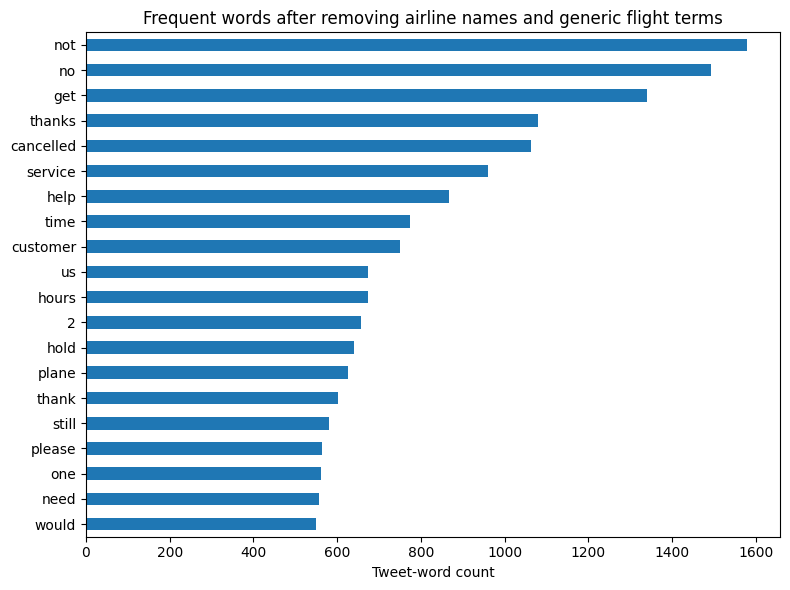

In [7]:
from nltk.corpus import stopwords
raw_words = [w.lower() for row in df["tokens_raw"] for w in row if re.search("[a-z]", w)]
clean_words = [w for row in df["tokens_clean"] for w in row]
print("Top raw words:", Counter(raw_words).most_common(20))
print("Top cleaned words:", Counter(clean_words).most_common(20))
airline_stop = {"united","americanair","usairways","southwest","delta","virginamerica","flight","flights"}
filtered_words = [w for w in clean_words if w not in airline_stop]
freq = pd.Series(Counter(filtered_words)).sort_values(ascending=False).head(20)
freq.sort_values().plot(kind="barh", figsize=(8,6), title="Frequent words after removing airline names and generic flight terms")
plt.xlabel("Tweet-word count"); plt.tight_layout(); plt.show()

## B6

In [8]:
pos = df.loc[df.airline_sentiment=="positive","clean_text"]
neg = df.loc[df.airline_sentiment=="negative","clean_text"]
vec = TfidfVectorizer(ngram_range=(1,1), min_df=5, max_df=0.8)
X = vec.fit_transform(pd.concat([pos,neg]))
terms = np.array(vec.get_feature_names_out())
pmean = X[:len(pos)].mean(axis=0).A1
nmean = X[len(pos):].mean(axis=0).A1
diff = pd.DataFrame({"word":terms, "negative_score":nmean, "positive_score":pmean})
diff["difference"] = diff.negative_score-diff.positive_score
display(diff.nlargest(15,"difference")[["word","difference"]])
display(diff.nsmallest(15,"difference")[["word","difference"]])

,word,difference
1518,not,0.021065
1507,no,0.020611
930,flight,0.019950
402,cancelled,0.017407
1129,hours,0.015872
1107,hold,0.015695
650,delayed,0.012058
1011,get,0.011543
1128,hour,0.011223
938,flightled,0.011092


,word,difference
2170,thanks,-0.084575
2167,thank,-0.082221
1039,great,-0.031934
1348,love,-0.019077
278,awesome,-0.017973
1474,much,-0.015836
320,best,-0.015334
193,amazing,-0.012079
1033,good,-0.011906
228,appreciate,-0.009760


## B7

In [9]:
neg_text = df.loc[df.airline_sentiment=="negative","clean_text"]
bigram = CountVectorizer(ngram_range=(2,2), min_df=8, max_features=40)
B = bigram.fit_transform(neg_text)
counts = np.asarray(B.sum(axis=0)).ravel()
phrases = pd.DataFrame({"phrase":bigram.get_feature_names_out(),"count":counts}).sort_values("count",ascending=False)
display(phrases.head(25))
# Search for contrast/negation examples such as "not good", "no problem", "not bad".
for phrase in ["not good","not helpful","no problem","not bad","never again"]:
    print(phrase, int(df["text"].str.contains(phrase, case=False, regex=False).sum()))

,phrase,count
8,customer service,450
6,cancelled flightled,448
23,late flight,221
5,cancelled flighted,204
11,flight cancelled,190
24,late flightr,145
28,no one,126
4,cancelled flight,124
2,call back,104
12,flight delayed,97


not good 21
not helpful 16
no problem 14
not bad 2
never again 25


## B8

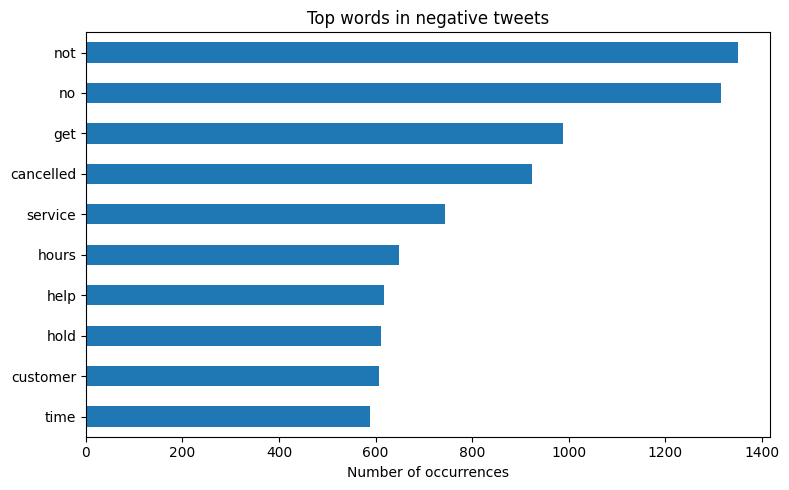

Recommendation: use the bar chart; it gives comparable values and is easier to read accurately.


In [10]:
# A bar chart is recommended for the Director because exact counts are readable.
top_neg = pd.Series(Counter(w for row in df.loc[df.airline_sentiment=="negative","tokens_clean"] for w in row
                            if w not in airline_stop)).sort_values(ascending=False).head(10)
top_neg.sort_values().plot(kind="barh", figsize=(8,5), title="Top words in negative tweets")
plt.xlabel("Number of occurrences"); plt.tight_layout(); plt.show()
print("Recommendation: use the bar chart; it gives comparable values and is easier to read accurately.")

# Part C

## C9

In [11]:
from nltk.sentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()
df["vader_compound"] = df["text"].apply(lambda x: sia.polarity_scores(x)["compound"])
def vader_label(score):
    if score >= 0.05: return "positive"
    if score <= -0.05: return "negative"
    return "neutral"
df["vader_sentiment"] = df["vader_compound"].apply(vader_label)
print("Overall agreement:", round(accuracy_score(df.airline_sentiment, df.vader_sentiment),3))
print(classification_report(df.airline_sentiment, df.vader_sentiment, zero_division=0))
display(pd.DataFrame(confusion_matrix(df.airline_sentiment, df.vader_sentiment,
    labels=["negative","neutral","positive"]),
    index=["Human negative","Human neutral","Human positive"],
    columns=["VADER negative","VADER neutral","VADER positive"]))

Overall agreement: 0.543
              precision    recall  f1-score   support

    negative       0.90      0.50      0.64      9178
     neutral       0.38      0.43      0.41      3099
    positive       0.34      0.87      0.49      2363

    accuracy                           0.54     14640
   macro avg       0.54      0.60      0.51     14640
weighted avg       0.70      0.54      0.57     14640



,VADER negative,VADER neutral,VADER positive
Human negative,4564,1904,2710
Human neutral,431,1325,1343
Human positive,89,215,2059


## C10

In [12]:
mismatch = df[df.airline_sentiment != df.vader_sentiment].copy()
def cause(t):
    s=t.lower()
    if re.search(r"\\b(not|no|never)\\b",s): return "Negation"
    if re.search(r"(yeah right|great job|love being|thanks for nothing|just wonderful)",s): return "Possible sarcasm"
    if re.search(r"\\b(but|however|although)\\b",s): return "Mixed feelings"
    if re.search(r"\\b(delayed|delay|cancelled|canceled|lost luggage|late flight)\\b",s): return "Airline operational wording"
    return "Other / context"
mismatch["disagreement_cause"] = mismatch.text.apply(cause)
display(mismatch["disagreement_cause"].value_counts())
display(mismatch[["text","airline_sentiment","vader_sentiment","vader_compound","disagreement_cause"]].head(15))

,count
disagreement_cause,
Other / context,6666
Possible sarcasm,26


,text,airline_sentiment,vader_sentiment,vader_compound,disagreement_cause
1,@VirginAmerica plus you've added commercials t...,positive,neutral,0.0000,Other / context
7,@VirginAmerica Really missed a prime opportuni...,neutral,positive,0.1458,Other / context
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",positive,negative,-0.3477,Other / context
10,@VirginAmerica did you know that suicide is th...,neutral,negative,-0.8555,Other / context
13,@VirginAmerica @virginmedia I'm flying your #f...,positive,neutral,0.0000,Other / context
16,@VirginAmerica So excited for my first cross c...,positive,negative,-0.5566,Other / context
17,@VirginAmerica I flew from NYC to SFO last we...,negative,positive,0.5754,Other / context
18,I ❤️ flying @VirginAmerica. ☺️👍,positive,neutral,0.0000,Other / context
20,@VirginAmerica why are your first fares in May...,negative,neutral,0.0000,Other / context
23,@VirginAmerica will you be making BOS&gt;LAS n...,neutral,negative,-0.2960,Other / context


## C11

In [13]:
test_tweets = [
    "Great, another three-hour delay. Just what I needed.",
    "I am not unhappy with the helpful crew, but the flight was late.",
    "The flight was cancelled and the staff were wonderful."
]
for t in test_tweets:
    print("\\nTweet:", t)
    print("VADER:", sia.polarity_scores(t), "=>", vader_label(sia.polarity_scores(t)["compound"]))

\nTweet: Great, another three-hour delay. Just what I needed.
VADER: {'neg': 0.202, 'neu': 0.439, 'pos': 0.36, 'compound': 0.4215} => positive
\nTweet: I am not unhappy with the helpful crew, but the flight was late.
VADER: {'neg': 0.0, 'neu': 0.737, 'pos': 0.263, 'compound': 0.3749} => positive
\nTweet: The flight was cancelled and the staff were wonderful.
VADER: {'neg': 0.157, 'neu': 0.551, 'pos': 0.291, 'compound': 0.4019} => positive


## C12

In [14]:
high = df[df.airline_sentiment_confidence >= 0.80]
print("Tweets retained:", len(high), "of", len(df))
print("Agreement on all labels:", round(accuracy_score(df.airline_sentiment,df.vader_sentiment),3))
print("Agreement on high-confidence labels:", round(accuracy_score(high.airline_sentiment,high.vader_sentiment),3))
print(classification_report(high.airline_sentiment,high.vader_sentiment,zero_division=0))

Tweets retained: 10459 of 14640
Agreement on all labels: 0.543
Agreement on high-confidence labels: 0.586
              precision    recall  f1-score   support

    negative       0.94      0.54      0.69      7392
     neutral       0.33      0.48      0.39      1550
    positive       0.35      0.92      0.50      1517

    accuracy                           0.59     10459
   macro avg       0.54      0.65      0.53     10459
weighted avg       0.77      0.59      0.62     10459



# Part D


## D13

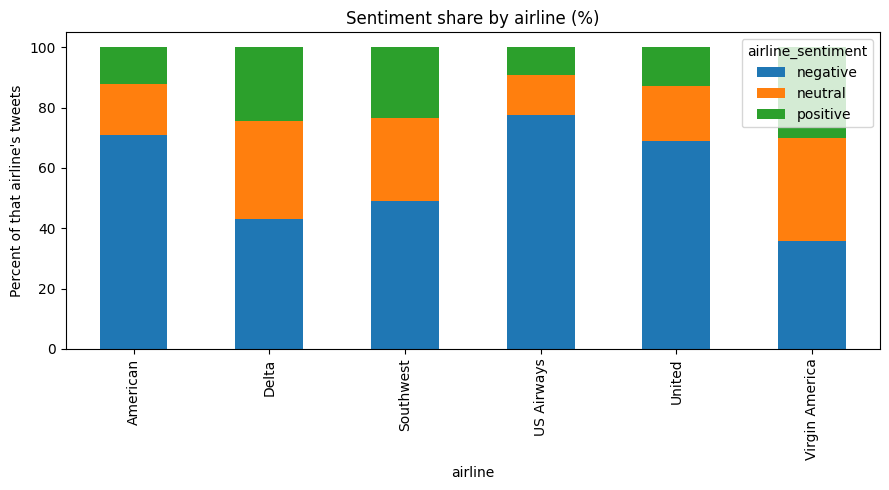

negativereason,Bad Flight,Can't Tell,Cancelled Flight,Customer Service Issue,Damaged Luggage,Flight Attendant Complaints,Flight Booking Problems,Late Flight,Lost Luggage,longlines
airline,,,,,,,,,,
American,4.4,10.1,12.6,39.2,0.6,4.4,6.6,12.7,7.6,1.7
Delta,6.7,19.5,5.3,20.8,1.2,6.3,4.6,28.2,6.0,1.5
Southwest,7.6,13.4,13.7,33.0,1.2,3.2,5.1,12.8,7.6,2.4
US Airways,4.6,10.9,8.4,35.8,0.5,5.4,5.4,20.0,6.8,2.2
United,8.2,14.4,6.9,25.9,0.8,6.4,5.5,19.9,10.2,1.8
Virgin America,10.5,12.2,9.9,33.1,2.2,2.8,15.5,9.4,2.8,1.7


In [15]:
mix = pd.crosstab(df.airline,df.airline_sentiment,normalize="index")*100
mix.plot(kind="bar",stacked=True,figsize=(9,5),title="Sentiment share by airline (%)")
plt.ylabel("Percent of that airline's tweets"); plt.tight_layout(); plt.show()
reason_mix = pd.crosstab(df.loc[df.airline_sentiment=="negative","airline"],
                         df.loc[df.airline_sentiment=="negative","negativereason"],normalize="index")*100
display(reason_mix.round(1))

## D14

airline_sentiment,negative,neutral,positive,total_tweets,negative_share_pct
airline,,,,,
United,2633,697,492,3822,68.890633
US Airways,2263,381,269,2913,77.686234
American,1960,463,336,2759,71.040232
Southwest,1186,664,570,2420,49.008264
Delta,955,723,544,2222,42.979298
Virgin America,181,171,152,504,35.912698


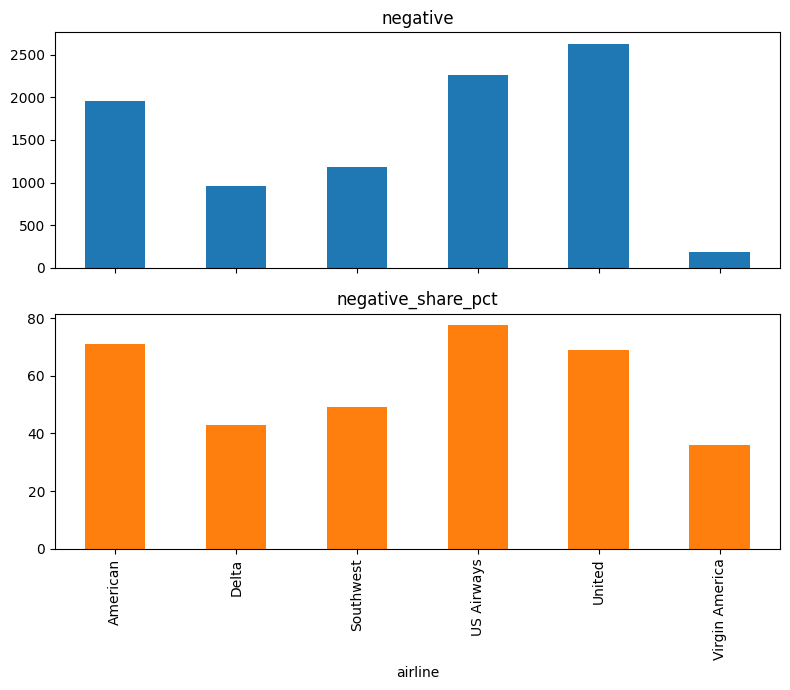

In [16]:
airline_stats = pd.crosstab(df.airline,df.airline_sentiment)
airline_stats["total_tweets"] = airline_stats.sum(axis=1)
airline_stats["negative_share_pct"] = airline_stats["negative"]/airline_stats["total_tweets"]*100
display(airline_stats.sort_values("negative",ascending=False))
airline_stats[["negative","negative_share_pct"]].plot(kind="bar",subplots=True,layout=(2,1),figsize=(8,7),legend=False)
plt.tight_layout(); plt.show()

## D15

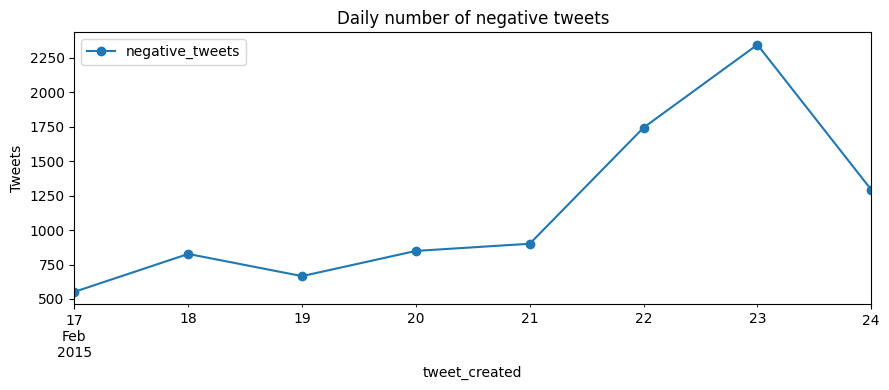

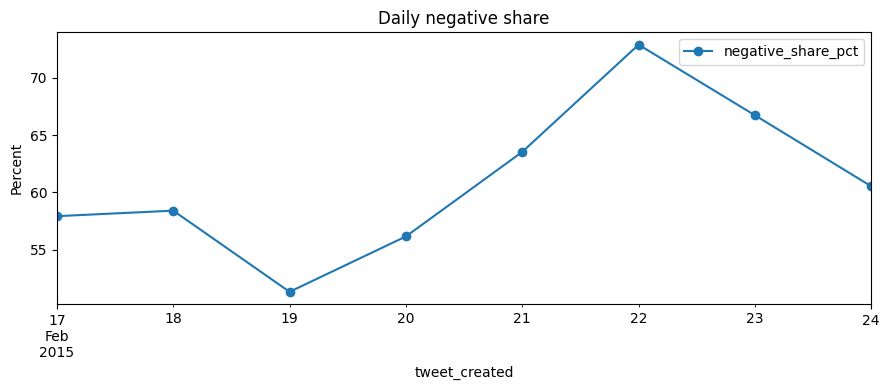

,negative_tweets,all_tweets,negative_share_pct
tweet_created,,,
2015-02-17 00:00:00+00:00,552,953,57.922350
2015-02-18 00:00:00+00:00,827,1416,58.403955
2015-02-19 00:00:00+00:00,666,1298,51.309707
2015-02-20 00:00:00+00:00,849,1512,56.150794
2015-02-21 00:00:00+00:00,901,1418,63.540197
2015-02-22 00:00:00+00:00,1744,2392,72.909699
2015-02-23 00:00:00+00:00,2346,3515,66.742532
2015-02-24 00:00:00+00:00,1293,2136,60.533708


A spike is an association in time; this short observational dataset cannot establish its cause.


In [17]:
daily = df.set_index("tweet_created").groupby(pd.Grouper(freq="D")).agg(
    negative_tweets=("airline_sentiment",lambda x:(x=="negative").sum()),
    all_tweets=("airline_sentiment","size"))
daily["negative_share_pct"] = daily.negative_tweets/daily.all_tweets*100
daily[["negative_tweets"]].plot(figsize=(9,4),marker="o",title="Daily number of negative tweets")
plt.ylabel("Tweets"); plt.tight_layout(); plt.show()
daily[["negative_share_pct"]].plot(figsize=(9,4),marker="o",title="Daily negative share")
plt.ylabel("Percent"); plt.tight_layout(); plt.show()
display(daily)
print("A spike is an association in time; this short observational dataset cannot establish its cause.")

## D16

In [18]:
# Example triage score: negative label + high label confidence + operational urgency + retweets.
urgent_terms = r"\\b(stranded|cancelled|canceled|missed connection|lost luggage|wheelchair|safety|overbooked)\\b"
df["urgent_keyword"] = df.text.str.contains(urgent_terms,case=False,na=False)
df["reply_priority"] = (
    (df.airline_sentiment=="negative").astype(int)*2
    + (df.airline_sentiment_confidence>=0.80).astype(int)
    + df.urgent_keyword.astype(int)*2
    + (df.retweets_count if "retweets_count" in df.columns else df.retweet_count).clip(upper=5).fillna(0).astype(int)*0.2
)
display(df[df.airline_sentiment=="negative"].sort_values("reply_priority",ascending=False)
        [["airline","text","negativereason","airline_sentiment_confidence","retweet_count","reply_priority"]].head(15))
print("Respond first to safety/accessibility, stranded/cancelled/lost-bag cases, high-confidence negatives, and widely shared complaints.")

/tmp/ipykernel_892/240625412.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["urgent_keyword"] = df.text.str.contains(urgent_terms,case=False,na=False)


,airline,text,negativereason,airline_sentiment_confidence,retweet_count,reply_priority
11596,US Airways,@USAirways 5 hr flight delay and a delay when ...,Late Flight,1.0,44,4.0
12680,American,@AmericanAir Cancelled Flight my flight saying...,Cancelled Flight,1.0,5,4.0
11582,US Airways,@USAirways of course never again tho . Thanks ...,Can't Tell,1.0,32,4.0
7132,Delta,STOP. USING.THIS.WORD. IF. YOU'RE. A. COMPANY....,Can't Tell,1.0,31,4.0
4127,United,@united @UnitedAppeals @gg8929 What kind of hy...,Flight Booking Problems,1.0,5,4.0
9589,US Airways,@USAirways you denied a mom her AM flight beca...,Can't Tell,1.0,4,3.8
6486,Southwest,@SouthwestAir very poor customer service thru ...,Customer Service Issue,1.0,4,3.8
12681,American,@AmericanAir Again you guys are a huge joke an...,Cancelled Flight,1.0,4,3.8
11388,US Airways,@USAirways @DRVRugby team is back home but lu...,Damaged Luggage,1.0,4,3.8
12678,American,@AmericanAir This is getting a bit ridiculous ...,Cancelled Flight,1.0,4,3.8


Respond first to safety/accessibility, stranded/cancelled/lost-bag cases, high-confidence negatives, and widely shared complaints.


# Part E

## E17

In [19]:
print("Airlines in this file:", sorted(df.airline.dropna().unique()))
print("Date range:", df.tweet_created.min(), "to", df.tweet_created.max())
print("Tweets by airline:")
display(df.airline.value_counts())
print("This is a social-media sample, not a random sample of all passengers.")

Airlines in this file: ['American', 'Delta', 'Southwest', 'US Airways', 'United', 'Virgin America']
Date range: 2015-02-17 07:36:05+00:00 to 2015-02-24 19:53:37+00:00
Tweets by airline:


,count
airline,
United,3822
US Airways,2913
American,2759
Southwest,2420
Delta,2222
Virgin America,504


This is a social-media sample, not a random sample of all passengers.


## E18

In [20]:
print("The data covers only February 2015. Re-run the same analysis on recent data before making current operational decisions.")
print("Likely to change: airline rankings, complaint topics, language, platform usage, and sentiment patterns.")
print("More stable but still needs checking: the need to preserve negation, inspect context, and compare complaint shares rather than raw counts.")

The data covers only February 2015. Re-run the same analysis on recent data before making current operational decisions.
Likely to change: airline rankings, complaint topics, language, platform usage, and sentiment patterns.
More stable but still needs checking: the need to preserve negation, inspect context, and compare complaint shares rather than raw counts.


## E19

In [21]:
print("Recommendation: do not fully replace the human team. Use automated scoring to triage large volumes, then let people review high-impact, sarcastic, mixed, ambiguous, and low-confidence cases.")
print("Monitor class-level precision/recall and disagreement causes over time before expanding automation.")

Recommendation: do not fully replace the human team. Use automated scoring to triage large volumes, then let people review high-impact, sarcastic, mixed, ambiguous, and low-confidence cases.
Monitor class-level precision/recall and disagreement causes over time before expanding automation.


# Part F

## Part F – Additional insights for the Director

The statements in Parts A–E point to findings. This part goes further with **three insights that are not covered by any earlier statement**. They answer the Director's three questions directly:

1. **Who** is most likely to complain in the future?
2. **Which area** is the biggest problem and needs to be addressed first?
3. **How much would feedback improve** if that area were addressed?

Each insight has a short written summary (Observation, Evidence, Why it matters, Recommended action, Confidence and limits), followed by a dashboard that shows the evidence.

| # | Insight | Headline number | Chart type used (from the visualization table) |
|---|---------|-----------------|-----------------------------------------------|
| 1 | Passengers who have complained once are the most likely to complain again | 74% of their later tweets are negative (vs 26%) | Bar charts, grouped bar chart |
| 2 | Customer service is the biggest problem area, led by American and US Airways | 32% of all negative tweets | Bar chart, heatmap (reason × airline) |
| 3 | Fixing customer service gives about twice the gain of any other single fix | Negative share 62.7% → about 52–53% | Before/after bar charts |


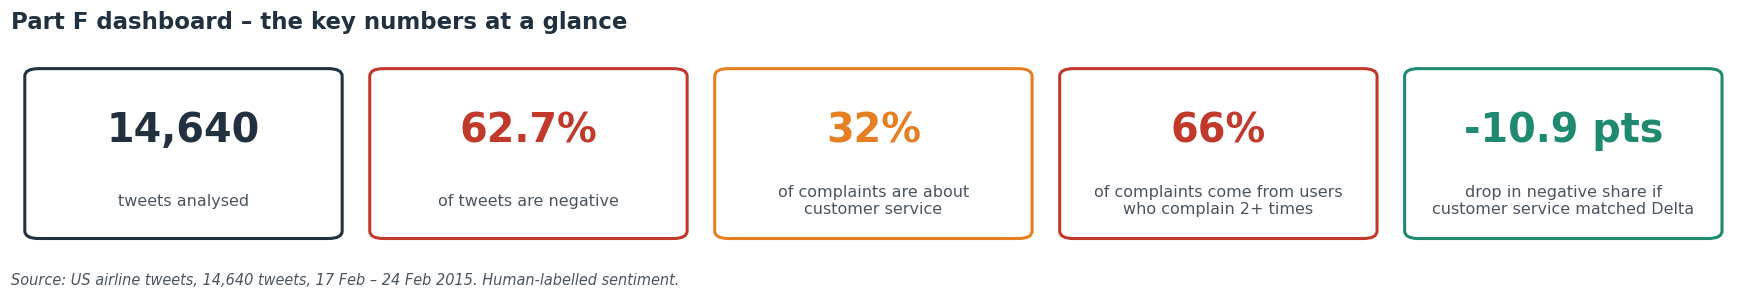

In [22]:
# ---------- Part F setup: derived columns, colours and helpers ----------
import textwrap
from matplotlib.gridspec import GridSpec
from matplotlib.patches import FancyBboxPatch

F = df.copy()
F["neg"] = (F["airline_sentiment"] == "negative").astype(int)
F["reason"] = F["negativereason"].where(F["neg"] == 1)          # reason only for negative tweets
F["reason"] = F["reason"].replace({"longlines": "Long lines"})

NEG, POS, NEU, DARK, HI = "#C0392B", "#1F8A70", "#9AA5B1", "#22313F", "#E67E22"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "figure.dpi": 110})

N_TWEETS = len(F)
DATE_RANGE = f"{F.tweet_created.min():%d %b} – {F.tweet_created.max():%d %b %Y}"
SOURCE = f"Source: US airline tweets, {N_TWEETS:,} tweets, {DATE_RANGE}. Human-labelled sentiment."

def caption(fig, text, y=0.015):
    fig.text(0.01, y, "\n".join(textwrap.wrap(text, 190)), ha="left", va="bottom",
             fontsize=9.5, color="#4A5560", style="italic")

def label_bars(ax, fmt="{:.1f}%", pad=1, horizontal=False, color=DARK):
    for p in ax.patches:
        if horizontal:
            ax.text(p.get_width() + pad, p.get_y() + p.get_height()/2, fmt.format(p.get_width()),
                    va="center", fontsize=9.5, color=color)
        else:
            ax.text(p.get_x() + p.get_width()/2, p.get_height() + pad, fmt.format(p.get_height()),
                    ha="center", va="bottom", fontsize=9.5, color=color)

# ---------- Numbers reused across the three dashboards ----------
total_neg = int(F["neg"].sum())
neg_rate  = total_neg / N_TWEETS * 100
cs_n      = int((F["reason"] == "Customer Service Issue").sum())
user_neg  = F[F.neg == 1].groupby("name").size()
repeat_neg_share = user_neg[user_neg >= 2].sum() / total_neg * 100

# ---------- Headline KPI strip ----------
cs_rate_air = (F["reason"] == "Customer Service Issue").groupby(F["airline"]).mean() * 100
neg_rate_air = F.groupby("airline")["neg"].mean() * 100
bench = cs_rate_air["Delta"]                                         # best large airline
gain_air = (cs_rate_air - bench).clip(lower=0)                       # points of negativity removed
tweets_removed = (gain_air / 100 * F["airline"].value_counts()).sum()
neg_after_bench = (total_neg - tweets_removed) / N_TWEETS * 100

kpis = [(f"{N_TWEETS:,}", "tweets analysed", DARK),
        (f"{neg_rate:.1f}%", "of tweets are negative", NEG),
        (f"{cs_n/total_neg*100:.0f}%", "of complaints are about\ncustomer service", HI),
        (f"{repeat_neg_share:.0f}%", "of complaints come from users\nwho complain 2+ times", NEG),
        (f"-{neg_rate-neg_after_bench:.1f} pts", "drop in negative share if\ncustomer service matched Delta", POS)]
fig = plt.figure(figsize=(16, 2.6)); ax = fig.add_axes([0.01, 0.14, 0.98, 0.66]); ax.axis("off"); ax.set_xlim(0, 5); ax.set_ylim(0, 1)
for i, (big, small, col) in enumerate(kpis):
    ax.add_patch(FancyBboxPatch((i + 0.04, 0.05), 0.92, 0.9, boxstyle="round,pad=0.0,rounding_size=0.04",
                                fc="white", ec=col, lw=2))
    ax.text(i + 0.5, 0.62, big, ha="center", va="center", fontsize=26, fontweight="bold", color=col)
    ax.text(i + 0.5, 0.25, small, ha="center", va="center", fontsize=10.5, color="#4A5560")
fig.suptitle("Part F dashboard – the key numbers at a glance", x=0.01, y=0.97, ha="left", fontsize=15, fontweight="bold", color=DARK)
caption(fig, SOURCE, y=0.0)
plt.show()


### Insight 1 – Who is more likely to complain in the future?

| Element | What I found |
|---|---|
| **Observation** | Passengers who have already complained once, and passengers of US Airways, American and United, are the most likely to complain again. |
| **Evidence** | • Among 3,000 users with at least two tweets, **74.1%** of their later tweets were negative if their first tweet was negative, against **26.1%** if it was not (Panel B).<br>• Negative share rises with how often a person tweets: **53.9%** (1 tweet), **61.4%** (2), **68.0%** (3–5), **71.3%** (6+) (Panel A).<br>• The same pattern holds inside every airline (Panel C). For Delta it goes from 33% to 52%, and for US Airways from 75% to 80%.<br>• Just **1,873 users with 2+ negative tweets wrote 6,078 of the 9,178 negative tweets (66%)**. |
| **Why it matters** | Two-thirds of the negative feedback comes from a small group of repeat complainers, and the first complaint is the best early warning of more to come. A quick fix at the first complaint could prevent many later ones. |
| **Recommended action** | Flag every first-time complainer for a fast, personal reply. Escalate anyone who has tweeted twice. Start with US Airways, American and United, where a first complaint is followed by negative tweets about 75–82% of the time. |
| **Confidence and limits** | **Moderate.** Users are matched by display name, so two people may be merged into one. "Future" only means later in the same week. People who tweet often may simply be more vocal in general. This is a correlation, not proof that a poor first reply causes the next complaint. |


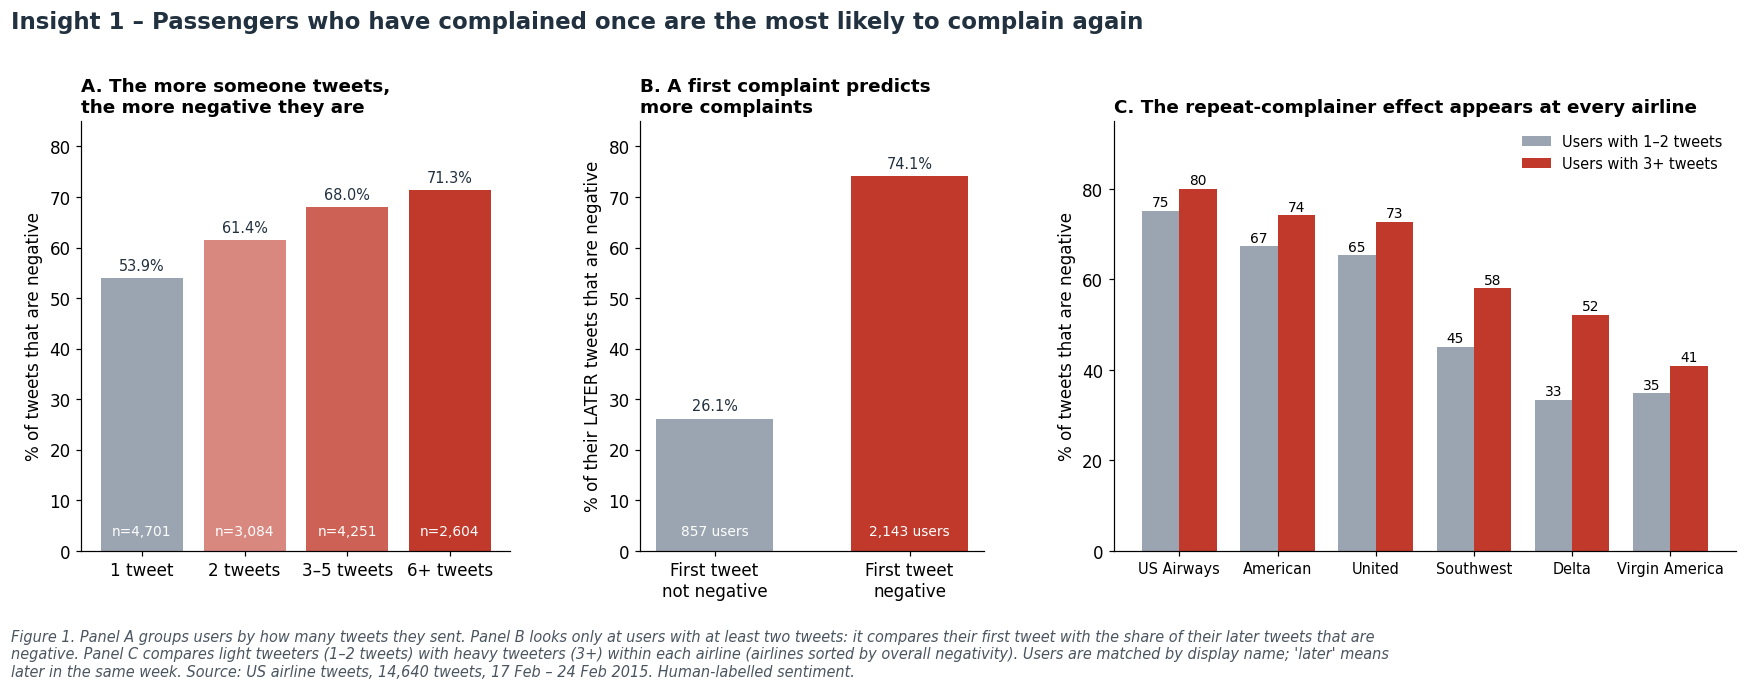

In [23]:
# ---------- Dashboard 1: who is likely to complain again? ----------
F["user_tweets"] = F.groupby("name")["tweet_id"].transform("size")
F["user_group"] = pd.cut(F["user_tweets"], [0, 1, 2, 5, 10_000], labels=["1 tweet", "2 tweets", "3–5 tweets", "6+ tweets"])
by_group = F.groupby("user_group", observed=True)["neg"].agg(["mean", "size"])

d = F.sort_values("tweet_created").copy()
d["k"] = d.groupby("name").cumcount()
first = d[d.k == 0].set_index("name")["neg"]
later = d[d.k > 0].groupby("name")["neg"].mean()
J = pd.concat([first.rename("first_neg"), later.rename("later_neg")], axis=1).dropna()
by_first = J.groupby("first_neg")["later_neg"].agg(["mean", "size"])

F["rep"] = np.where(F["user_tweets"] >= 3, "3+ tweets", "1–2 tweets")
by_air = (F.pivot_table(index="airline", columns="rep", values="neg", aggfunc="mean") * 100)
by_air = by_air.loc[by_air.mean(axis=1).sort_values(ascending=False).index]

fig = plt.figure(figsize=(16, 6.3))
gs = GridSpec(1, 3, width_ratios=[1, 0.8, 1.45], wspace=0.28, figure=fig)

ax = fig.add_subplot(gs[0])
cols = [NEU, "#D98880", "#CD6155", NEG]
ax.bar(by_group.index.astype(str), by_group["mean"] * 100, color=cols)
label_bars(ax)
for i, n in enumerate(by_group["size"]): ax.text(i, 3, f"n={n:,}", ha="center", color="white", fontsize=9)
ax.set_ylim(0, 85); ax.set_ylabel("% of tweets that are negative")
ax.set_title("A. The more someone tweets,\nthe more negative they are", loc="left")

ax = fig.add_subplot(gs[1])
vals = by_first["mean"].reindex([0, 1]) * 100
ax.bar(["First tweet\nnot negative", "First tweet\nnegative"], vals, color=[NEU, NEG], width=0.6)
label_bars(ax)
for i, n in enumerate(by_first["size"].reindex([0, 1])): ax.text(i, 3, f"{n:,} users", ha="center", color="white", fontsize=9)
ax.set_ylim(0, 85); ax.set_ylabel("% of their LATER tweets that are negative")
ax.set_title("B. A first complaint predicts\nmore complaints", loc="left")

ax = fig.add_subplot(gs[2])
x = np.arange(len(by_air)); w = 0.38
ax.bar(x - w/2, by_air["1–2 tweets"], w, color=NEU, label="Users with 1–2 tweets")
ax.bar(x + w/2, by_air["3+ tweets"], w, color=NEG, label="Users with 3+ tweets")
for i, (a, b) in enumerate(zip(by_air["1–2 tweets"], by_air["3+ tweets"])):
    ax.text(i - w/2, a + 1, f"{a:.0f}", ha="center", fontsize=9); ax.text(i + w/2, b + 1, f"{b:.0f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(by_air.index, rotation=0, fontsize=9.5)
ax.set_ylim(0, 95); ax.set_ylabel("% of tweets that are negative"); ax.legend(frameon=False, loc="upper right", fontsize=9.5)
ax.set_title("C. The repeat-complainer effect appears at every airline", loc="left")

fig.suptitle("Insight 1 – Passengers who have complained once are the most likely to complain again",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=DARK)
fig.subplots_adjust(top=0.82, bottom=0.2, left=0.05, right=0.99)
caption(fig, "Figure 1. Panel A groups users by how many tweets they sent. Panel B looks only at users with at least two tweets: "
        "it compares their first tweet with the share of their later tweets that are negative. Panel C compares light tweeters (1–2 tweets) with heavy tweeters (3+) "
        "within each airline (airlines sorted by overall negativity). Users are matched by display name; 'later' means later in the same week. " + SOURCE)
plt.show()


### Insight 2 – Which section is the biggest problem?

| Element | What I found |
|---|---|
| **Observation** | Customer service is the biggest problem area, and it is concentrated at American and US Airways. |
| **Evidence** | • **Customer Service Issue = 2,910 negative tweets**, which is **31.7% of all negatives** and 19.9% of all tweets. The next reason, Late Flight, has 1,665 (18.1%) (Panel A).<br>• American and US Airways each have **27.8 customer-service complaints per 100 tweets**, against 9.0 for Delta, 11.9 for Virgin America, 16.2 for Southwest and 17.8 for United (Panel B).<br>• Other hotspots in the heatmap: American has 8.9 cancellations per 100 tweets (Delta 2.3), US Airways has 15.6 late-flight complaints per 100 tweets, and United has 7.0 lost-luggage complaints per 100 tweets, the highest of any airline. |
| **Why it matters** | Customer service is where a fix helps the most passengers, and it is also the area a company controls directly through staffing, training and response times. Delays and cancellations are partly outside its control. |
| **Recommended action** | Make customer service the first priority, starting with American and US Airways. Then target the airline-specific problems: cancellations at American, delays at US Airways and baggage at United. |
| **Confidence and limits** | **Moderate to high for the ranking, lower for the exact numbers.** The average label confidence for Customer Service Issue is only 0.78 (median 0.70), and 13% of negatives are labelled "Can't Tell". People often tweet at an airline's account to ask for help, which may inflate customer-service complaints. The data covers one week in February 2015. |


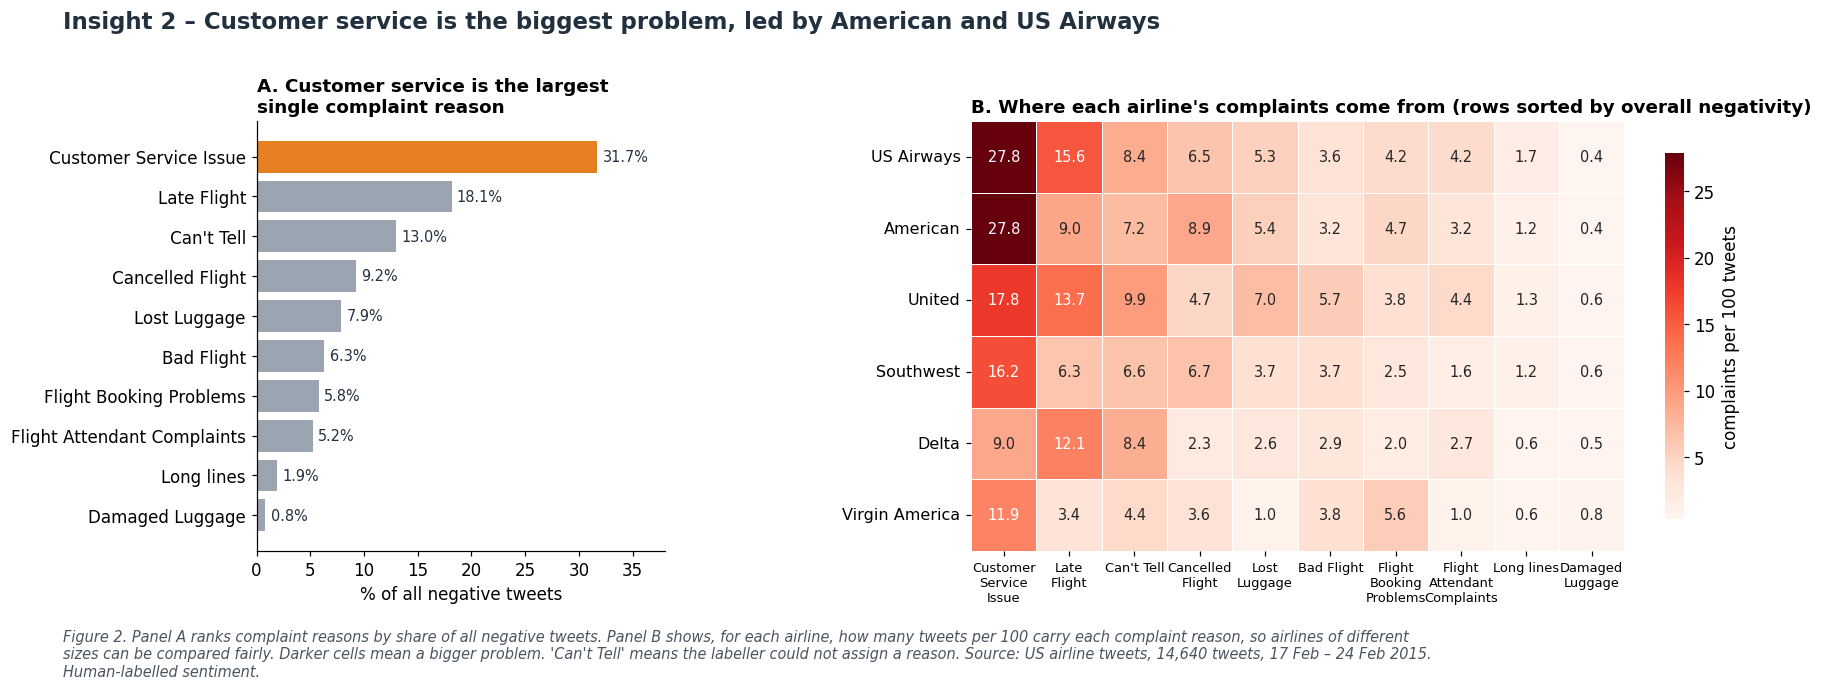

In [24]:
# ---------- Dashboard 2: which area needs fixing first? ----------
reason_share = (F["reason"].value_counts() / total_neg * 100)
order = list(reason_share.index)
rate = pd.crosstab(F["airline"], F["reason"]).div(F["airline"].value_counts(), axis=0)[order] * 100
rate = rate.loc[neg_rate_air.sort_values(ascending=False).index]

fig = plt.figure(figsize=(16, 6.3))
gs = GridSpec(1, 2, width_ratios=[0.8, 1.6], wspace=0.5, figure=fig)

ax = fig.add_subplot(gs[0])
rs = reason_share.sort_values()
ax.barh(rs.index, rs.values, color=[HI if r == "Customer Service Issue" else NEU for r in rs.index])
label_bars(ax, fmt="{:.1f}%", pad=0.5, horizontal=True)
ax.set_xlim(0, 38); ax.set_xlabel("% of all negative tweets")
ax.set_title("A. Customer service is the largest\nsingle complaint reason", loc="left")

ax = fig.add_subplot(gs[1])
sns.heatmap(rate, annot=True, fmt=".1f", cmap="Reds", linewidths=0.6, linecolor="white",
            cbar_kws={"label": "complaints per 100 tweets", "shrink": 0.85}, ax=ax, annot_kws={"fontsize": 9.5})
ax.set_xticklabels([textwrap.fill(t.get_text(), 10) for t in ax.get_xticklabels()], rotation=0, fontsize=8.5)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10.5)
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("B. Where each airline's complaints come from (rows sorted by overall negativity)", loc="left")

fig.suptitle("Insight 2 – Customer service is the biggest problem, led by American and US Airways",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=DARK)
fig.subplots_adjust(top=0.82, bottom=0.2, left=0.12, right=0.99)
caption(fig, "Figure 2. Panel A ranks complaint reasons by share of all negative tweets. Panel B shows, for each airline, how many tweets "
        "per 100 carry each complaint reason, so airlines of different sizes can be compared fairly. Darker cells mean a bigger problem. "
        "'Can't Tell' means the labeller could not assign a reason. " + SOURCE)
plt.show()


### Insight 3 – How much would feedback improve if we fix it?

| Element | What I found |
|---|---|
| **Observation** | Fixing customer service would improve overall feedback about twice as much as fixing any other single area. |
| **Evidence** | • Today **62.7%** of tweets are negative.<br>• If customer-service complaints were **halved** (and became neutral), this falls to **52.8%**, a drop of about **10 points**. Halving late flights gives 57.0%, and halving cancellations gives 59.8% (Panel A).<br>• Halving the top three reasons (customer service, late flight, cancelled flight) would give about 44.2%.<br>• If every airline brought its customer-service complaint rate down to **Delta's level (9.0 per 100 tweets)**, the overall negative share would fall to about **51.8%** (**-10.9 points**). American would go from 71.0% to 52.2% and US Airways from 77.7% to 58.8% (Panel B). |
| **Why it matters** | It lets the Director compare options by expected improvement before spending money. Customer service is the best single investment, and the Delta benchmark gives a target that another airline already achieves. |
| **Recommended action** | Fund the customer-service fix first. Use Delta's rate as the target for American and US Airways, and track the weekly negative share to check the effect. Look at late flights next. |
| **Confidence and limits** | **Low to moderate: this is arithmetic, not a forecast.** It assumes a fixed complaint becomes a neutral tweet, when the person might turn positive or stop tweeting. Halving is an illustrative target, not a proven achievable one. The data cannot show that Delta's lower rate is caused by better service. It covers one week in 2015, so re-run it on current data before acting. |


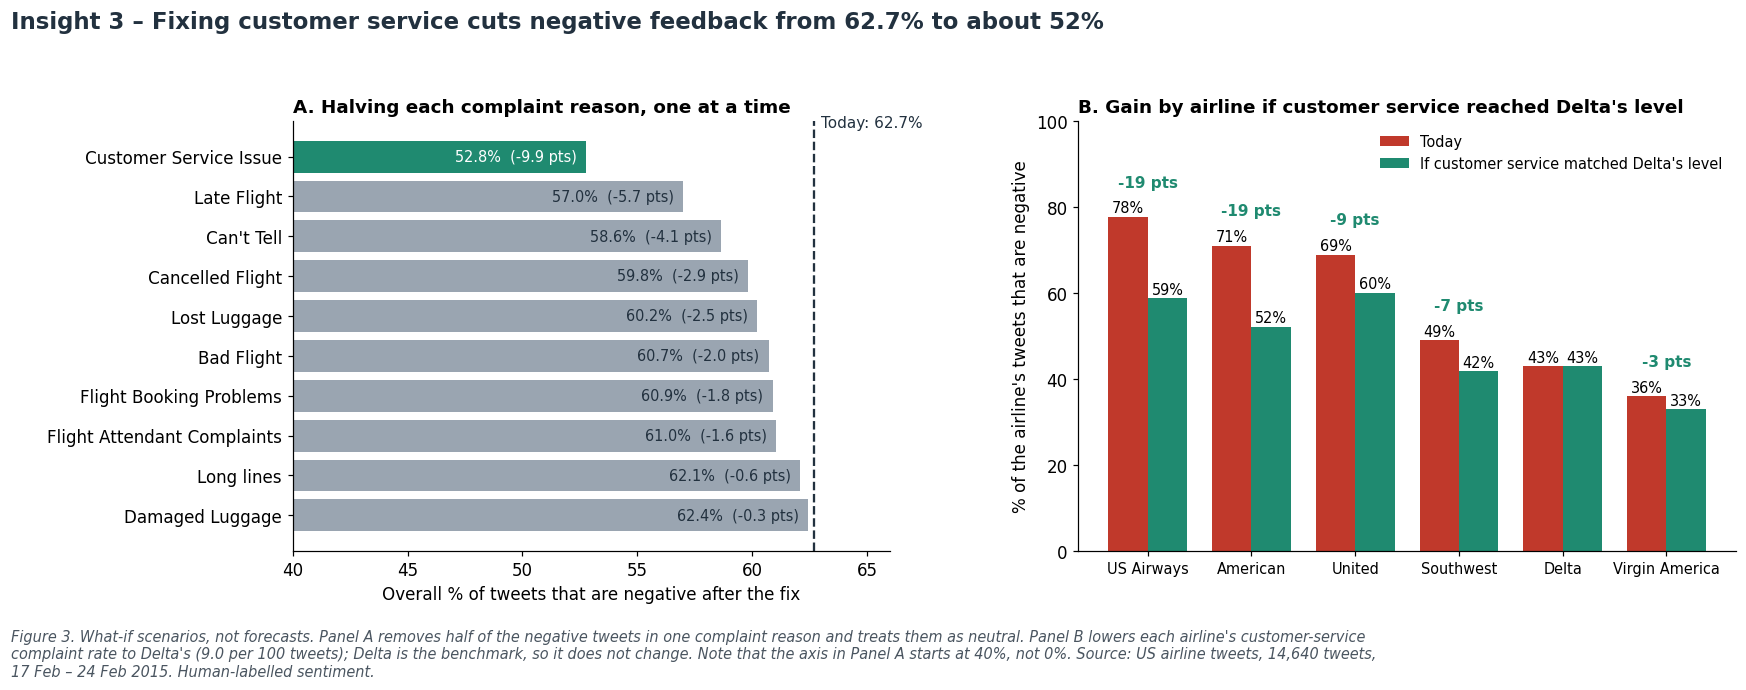

In [25]:
# ---------- Dashboard 3: how much would feedback improve? ----------
after_half = pd.Series({r: (total_neg - (F["reason"] == r).sum() / 2) / N_TWEETS * 100
                        for r in F["reason"].dropna().unique()}).sort_values(ascending=False)

fig = plt.figure(figsize=(16, 6.3))
gs = GridSpec(1, 2, width_ratios=[1, 1.1], wspace=0.3, figure=fig)

ax = fig.add_subplot(gs[0])
ax.barh(after_half.index, after_half.values, color=[POS if r == "Customer Service Issue" else NEU for r in after_half.index])
ax.axvline(neg_rate, color=DARK, ls="--", lw=1.5)
ax.text(neg_rate + 0.3, len(after_half) - 0.35, f"Today: {neg_rate:.1f}%", fontsize=10, color=DARK, va="bottom")
for p, r in zip(ax.patches, after_half.index):
    drop = neg_rate - p.get_width()
    ax.text(p.get_width() - 0.4, p.get_y() + p.get_height()/2, f"{p.get_width():.1f}%  (-{drop:.1f} pts)",
            va="center", ha="right", fontsize=9.5, color="white" if r == "Customer Service Issue" else DARK)
ax.set_xlim(40, 66); ax.set_xlabel("Overall % of tweets that are negative after the fix")
ax.set_title("A. Halving each complaint reason, one at a time", loc="left")

ax = fig.add_subplot(gs[1])
cmp_ = pd.DataFrame({"Today": neg_rate_air, "If customer service matched Delta": neg_rate_air - gain_air})
cmp_ = cmp_.sort_values("Today", ascending=False)
x = np.arange(len(cmp_)); w = 0.38
ax.bar(x - w/2, cmp_["Today"], w, color=NEG, label="Today")
ax.bar(x + w/2, cmp_["If customer service matched Delta"], w, color=POS, label="If customer service matched Delta's level")
for i, (a, b) in enumerate(zip(cmp_["Today"], cmp_["If customer service matched Delta"])):
    ax.text(i - w/2, a + 1, f"{a:.0f}%", ha="center", fontsize=9.5)
    ax.text(i + w/2, b + 1, f"{b:.0f}%", ha="center", fontsize=9.5)
    if a - b > 0.05: ax.text(i, max(a, b) + 7, f"-{a-b:.0f} pts", ha="center", fontsize=10, fontweight="bold", color=POS)
ax.set_xticks(x); ax.set_xticklabels(cmp_.index, fontsize=9.5)
ax.set_ylim(0, 100); ax.set_ylabel("% of the airline's tweets that are negative"); ax.legend(frameon=False, loc="upper right", fontsize=9.5)
ax.set_title("B. Gain by airline if customer service reached Delta's level", loc="left")

fig.suptitle(f"Insight 3 – Fixing customer service cuts negative feedback from {neg_rate:.1f}% to about {neg_after_bench:.0f}%",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=DARK)
fig.subplots_adjust(top=0.82, bottom=0.2, left=0.17, right=0.99)
caption(fig, "Figure 3. What-if scenarios, not forecasts. Panel A removes half of the negative tweets in one complaint reason and treats them as neutral. "
        f"Panel B lowers each airline's customer-service complaint rate to Delta's ({bench:.1f} per 100 tweets); Delta is the benchmark, so it does not change. "
        "Note that the axis in Panel A starts at 40%, not 0%. " + SOURCE)
plt.show()
